# 📊 For1Sight: Exploratory Data Analysis (EDA)
**Phase 2: Data Profiling & Statistical Visualization**
This notebook explores the cleaned Parquet data warehouse to uncover statistical distributions, identify feature correlations, and validate data quality before feeding it into the XGBoost machine learning model.

In [1]:
from pyspark.sql import SparkSession
from pyspark.sql.functions import col, isnan, when, count
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual style for academic report charts
sns.set_theme(style="darkgrid")
plt.rcParams['figure.figsize'] = (10, 6)

# Initialize Spark (Reusing the local temp dir to prevent Windows errors)
spark = SparkSession.builder \
    .appName("For1Sight_EDA") \
    .config("spark.driver.memory", "4g") \
    .config("spark.local.dir", "./spark_temp") \
    .getOrCreate()

spark.sparkContext.setLogLevel("WARN")
print("✅ Spark Session & Visualization Libraries Ready!")

✅ Spark Session & Visualization Libraries Ready!


In [2]:
# Use '../' to step out of the notebooks folder and into the main project folder
warehouse_path = "../for1sight_warehouse/hf_laptimes.parquet"
df = spark.read.parquet(warehouse_path)

print(f"Dataset loaded with {df.count():,} rows and {len(df.columns)} columns.")

# Display a subset of columns critical for Machine Learning
ml_columns = ["drv", "lap", "compound", "life", "time", "pos"]
print("\n--- CORE FEATURES PREVIEW ---")
df.select(ml_columns).show(5)

Dataset loaded with 197,413 rows and 47 columns.

--- CORE FEATURES PREVIEW ---
+---+---+--------+----+------+----+
|drv|lap|compound|life|  time| pos|
+---+---+--------+----+------+----+
|ALB|1.0|    SOFT| 1.0|99.757|15.0|
|ALB|2.0|    SOFT| 2.0| 91.71|15.0|
|ALB|3.0|    SOFT| 3.0|90.224|15.0|
|ALB|4.0|    SOFT| 4.0|90.874|15.0|
|ALB|5.0|    SOFT| 5.0|90.314|15.0|
+---+---+--------+----+------+----+
only showing top 5 rows



In [3]:
print("--- MISSING VALUES ANALYSIS ---")
# Count nulls or NaNs in the core machine learning columns
df.select([count(when(isnan(c) | col(c).isNull(), c)).alias(c) for c in ml_columns]).show()

print("--- NUMERICAL SUMMARY STATISTICS ---")
# Show mean, min, max, and standard deviation for numeric features
df.select("time", "life", "lap", "pos").describe().show()

--- MISSING VALUES ANALYSIS ---
+---+---+--------+----+-----+------+
|drv|lap|compound|life| time|   pos|
+---+---+--------+----+-----+------+
| 34|  0|       0| 961|28261|117574|
+---+---+--------+----+-----+------+

--- NUMERICAL SUMMARY STATISTICS ---
+-------+-----------------+-----------------+------------------+-----------------+
|summary|             time|             life|               lap|              pos|
+-------+-----------------+-----------------+------------------+-----------------+
|  count|           169152|           196452|            197413|            79839|
|   mean|98.22017155576029| 9.98639362286971|21.321219980447083|9.942747278898784|
| stddev|47.07515808523172|8.653515343640823| 18.53758139245603|5.532361199256356|
|    min|           63.971|              1.0|               1.0|              1.0|
|    max|         2526.253|             78.0|             165.0|             22.0|
+-------+-----------------+-----------------+------------------+-----------------

In [4]:
# Convert a 10% random sample to Pandas for safe memory usage on your laptop
# (Adjust fraction up or down depending on your dataset size)
print("Sampling data for visualizations...")
pandas_df = df.select(ml_columns).sample(fraction=0.1, seed=42).toPandas()

# Convert time (if it's in string or timedelta) to numeric seconds for plotting
# If your 'time' is already numeric, this will just ensure it's a float
pandas_df['time'] = pd.to_numeric(pandas_df['time'], errors='coerce')

# Drop rows where time couldn't be converted
pandas_df = pandas_df.dropna(subset=['time'])

print(f"✅ Pandas DataFrame ready with {len(pandas_df):,} rows for plotting.")
pandas_df.head()

Sampling data for visualizations...
✅ Pandas DataFrame ready with 16,828 rows for plotting.


,drv,lap,compound,life,time,pos
0,ALB,8.0,SOFT,8.0,91.974,17.0
1,ALB,17.0,HARD,9.0,90.133,16.0
2,ALB,19.0,HARD,11.0,90.047,15.0
3,ALB,51.0,MEDIUM,18.0,89.420,17.0
4,ALO,1.0,MEDIUM,2.0,94.980,5.0


C:\Users\ayepd\AppData\Local\Temp\ipykernel_92168\3839673821.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(data=pandas_df, x='compound', palette='viridis',


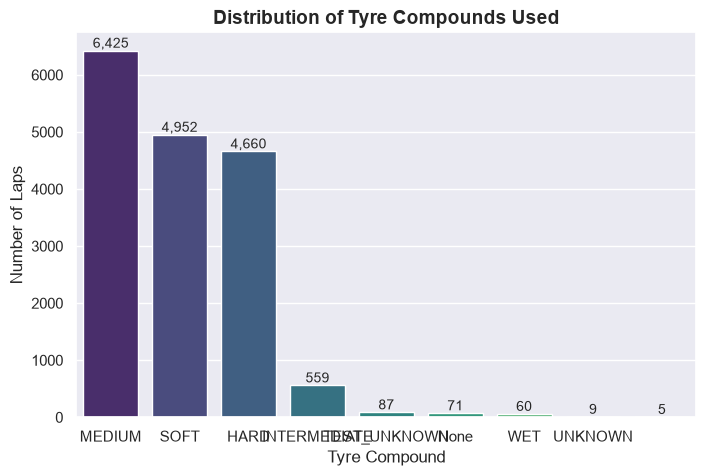

In [5]:
plt.figure(figsize=(8, 5))
ax = sns.countplot(data=pandas_df, x='compound', palette='viridis', 
                   order=pandas_df['compound'].value_counts().index)

plt.title('Distribution of Tyre Compounds Used', fontsize=14, fontweight='bold')
plt.xlabel('Tyre Compound', fontsize=12)
plt.ylabel('Number of Laps', fontsize=12)

# Add counts on top of bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height()):,}', (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10)

plt.show()

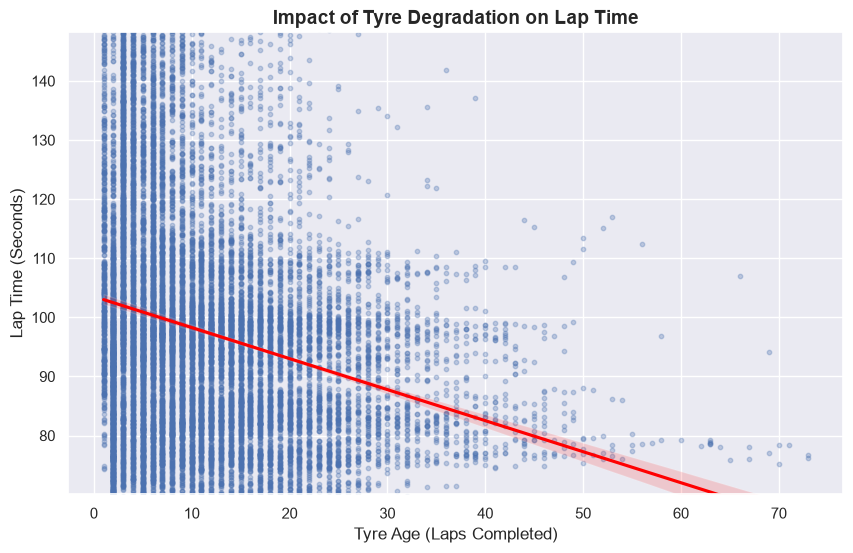

In [6]:
plt.figure(figsize=(10, 6))

# Use a scatter plot with a trendline (regplot)
sns.regplot(data=pandas_df, x='life', y='time', 
            scatter_kws={'alpha':0.3, 's':10}, line_kws={'color':'red'})

plt.title('Impact of Tyre Degradation on Lap Time', fontsize=14, fontweight='bold')
plt.xlabel('Tyre Age (Laps Completed)', fontsize=12)
plt.ylabel('Lap Time (Seconds)', fontsize=12)
plt.ylim(pandas_df['time'].quantile(0.01), pandas_df['time'].quantile(0.99)) # Filter extreme outliers

plt.show()

C:\Users\ayepd\AppData\Local\Temp\ipykernel_92168\1263526391.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=pandas_df, x='compound', y='time', palette='Set2', showfliers=False)


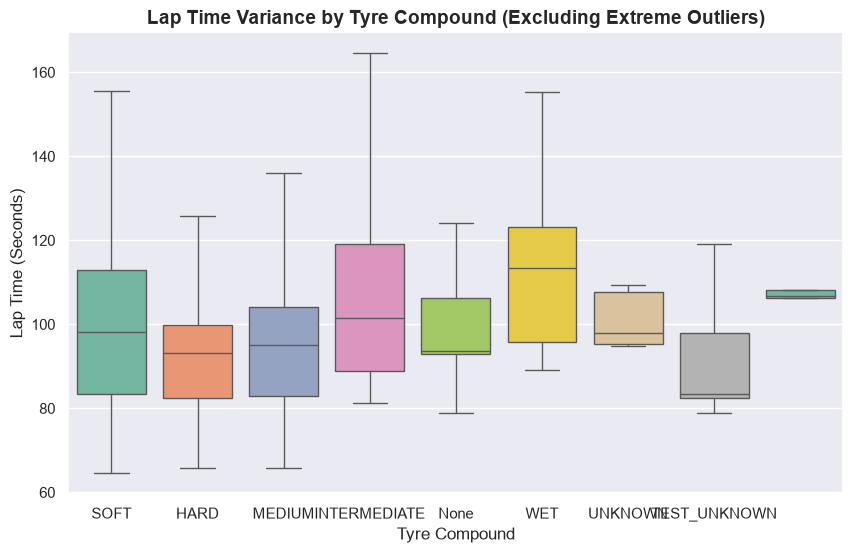

In [7]:
plt.figure(figsize=(10, 6))

sns.boxplot(data=pandas_df, x='compound', y='time', palette='Set2', showfliers=False)

plt.title('Lap Time Variance by Tyre Compound (Excluding Extreme Outliers)', fontsize=14, fontweight='bold')
plt.xlabel('Tyre Compound', fontsize=12)
plt.ylabel('Lap Time (Seconds)', fontsize=12)

plt.show()
